# Framework simulations: evaluation reference and well-energy correction

Two simulations with known ground truth, for the TCBB revision of the plate-design paper.

1. **Evaluation reference.** Scores of four predictors when responses are scored (a) against PBS, as published,
   (b) after centering on the inert proteins (our correction), and (c) after centering on the mean of all
   perturbations (Systema-style).
2. **Well-energy correction.** Bias of three estimators of the squared response norm: a single-half norm,
   the cross-half product A·B, and A·B minus the well energy estimated from replicate control wells
   (Propositions 1 and 2).

Outputs: `results/sim_framework_eval.csv`, `results/sim_framework_estimators.csv`,
`figures/FigS10_framework_sim.png`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from donorvar import well_noise

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
SEED = 20261119

## 1. Evaluation reference

Each active condition c has a true response r_c = alpha_c * b + s_c: a biological axis b shared by active
perturbations, with a perturbation-specific scale alpha_c, plus a perturbation-specific direction s_c.
Every condition, including the inert ones, also carries a technical offset o (the shared component that inert
wells show) and well noise. Inert conditions have no true response.

Predictors (each also predicts the inert conditions):
- **Context mean**: the same vector for every condition (mean observed response); ignores the perturbation.
- **Shared only**: alpha_c * b + o; knows the shared biology and the offset, nothing specific.
- **Specific only**: s_c plus noise; knows only the perturbation-specific part.
- **Full**: r_c + o plus noise.

Scores: mean Pearson correlation across genes over active conditions, after subtracting a reference from
observed and predicted responses: none (PBS, as published), the inert mean, or the mean of all conditions.
A zero vector is scored 0.

In [2]:
def pearson(a, b):
    a = a - a.mean(); b = b - b.mean()
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return 0.0 if na < 1e-12 or nb < 1e-12 else float(a @ b / (na * nb))


def unit(rng, G):
    v = rng.normal(size=G)
    return v / np.linalg.norm(v)


def eval_once(rng, G=500, n_active=40, n_inert=12, bio_norm=3.0, spec_norm=3.0, offset_norm=2.0,
              well_sd=0.08, pred_sd=0.08):
    b = unit(rng, G)
    alpha = rng.gamma(2, 1, n_active); alpha /= alpha.mean()
    S = np.stack([unit(rng, G) * spec_norm for _ in range(n_active)])
    R = alpha[:, None] * bio_norm * b + S                       # true active responses
    o = unit(rng, G) * offset_norm                               # technical shared component
    Y_act = R + o + rng.normal(0, well_sd, (n_active, G))
    Y_inert = o + rng.normal(0, well_sd, (n_inert, G))
    n = lambda k: rng.normal(0, pred_sd, (k, G))
    ctx = Y_act.mean(0)
    preds = {
        "Context mean": (np.tile(ctx, (n_active, 1)), np.tile(ctx, (n_inert, 1))),
        "Shared only": (alpha[:, None] * bio_norm * b + o, np.tile(o, (n_inert, 1))),
        "Specific only": (S + n(n_active), n(n_inert)),
        "Full": (R + o + n(n_active), o + n(n_inert)),
    }
    out = []
    for name, (P_act, P_inert) in preds.items():
        refs = {
            "PBS (published)": (0.0, 0.0),
            "Inert centering": (Y_inert.mean(0), P_inert.mean(0)),
            "All-perturbation centering": (np.vstack([Y_act, Y_inert]).mean(0), np.vstack([P_act, P_inert]).mean(0)),
        }
        for ref, (ry, rp) in refs.items():
            sc = np.mean([pearson(P_act[c] - rp, Y_act[c] - ry) for c in range(n_active)])
            out.append(dict(predictor=name, reference=ref, score=sc))
    return out


rng = np.random.default_rng(SEED)
rows = []
for offset_norm in [0.0, 1.0, 2.0, 4.0]:
    for bio_norm in [0.0, 3.0, 6.0]:
        for rep in range(20):
            for r in eval_once(rng, bio_norm=bio_norm, offset_norm=offset_norm):
                rows.append(dict(r, offset_norm=offset_norm, bio_norm=bio_norm, rep=rep))
ev = pd.DataFrame(rows)
ev.to_csv("results/sim_framework_eval.csv", index=False)
summary = (ev.groupby(["offset_norm", "bio_norm", "predictor", "reference"])["score"].mean()
             .unstack("reference").round(3))
summary

reference                           All-perturbation centering  \
offset_norm bio_norm predictor                                   
0.0         0.0      Context mean                        0.000   
                     Full                                0.737   
                     Shared only                         0.000   
                     Specific only                       0.737   
            3.0      Context mean                        0.000   
                     Full                                0.784   
                     Shared only                         0.349   
                     Specific only                       0.662   
            6.0      Context mean                        0.000   
                     Full                                0.834   
                     Shared only                         0.543   
                     Specific only                       0.565   
1.0         0.0      Context mean                        0.000   
                     Full                                0.737   
                     Shared only                         0.000   
                     Specific only                       0.737   
            3.0      Context mean                        0.000   
                     Full                                0.783   
                     Shared only                         0.348   
                     Specific only                       0.662   
            6.0      Context mean                        0.000   
                     Full                                0.832   
                     Shared only                         0.542   
                     Specific only                       0.567   
2.0         0.0      Context mean                        0.000   
                     Full                                0.737   
                     Shared only                         0.000   
                     Specific only                       0.737   
            3.0      Context mean                        0.000   
                     Full                                0.785   
                     Shared only                         0.358   
                     Specific only                       0.658   
            6.0      Context mean                        0.000   
                     Full                                0.830   
                     Shared only                         0.529   
                     Specific only                       0.573   
4.0         0.0      Context mean                        0.000   
                     Full                                0.738   
                     Shared only                         0.000   
                     Specific only                       0.737   
            3.0      Context mean                        0.000   
                     Full                                0.785   
                     Shared only                         0.361   
                     Specific only                       0.658   
            6.0      Context mean                        0.000   
                     Full                                0.828   
                     Shared only                         0.521   
                     Specific only                       0.575   

reference                           Inert centering  PBS (published)  
offset_norm bio_norm predictor                                        
0.0         0.0      Context mean             0.000            0.156  
                     Full                     0.723            0.738  
                     Shared only              0.000            0.000  
                     Specific only            0.723            0.738  
            3.0      Context mean             0.000            0.577  
                     Full                     0.824            0.835  
                     Shared only              0.562            0.564  
                     Specific only            0.561         

In [3]:
# Main setting used in the figure
main = ev[(ev.offset_norm == 2.0) & (ev.bio_norm == 3.0)]
main.groupby(["predictor", "reference"])["score"].agg(["mean", "std"]).round(3).unstack("reference")

mean                                  \
reference     All-perturbation centering Inert centering PBS (published)   
predictor                                                                  
Context mean                       0.000           0.000           0.663   
Full                               0.785           0.824           0.866   
Shared only                        0.358           0.559           0.688   
Specific only                      0.658           0.562           0.517   

                                     std                                  
reference     All-perturbation centering Inert centering PBS (published)  
predictor                                                                 
Context mean                       0.000           0.000           0.017  
Full                               0.007           0.004           0.004  
Shared only                        0.033           0.018           0.011  
Specific only                      0.009           0.007           0.007

## 2. Well-energy correction (Propositions 1 and 2)

One donor and cell type: six replicate control wells and one condition well, each with two halves of n cells.
Every well carries an independent well effect with per-gene SD `well_sd`, so the true well energy is
w = G * well_sd^2. Responses are computed against the mean of the control wells, half by half.
We compare three estimates of the true squared norm |z|^2:

- **Single half**: (|A|^2 + |B|^2) / 2, which contains the sampling noise;
- **Cross-half**: A·B, which removes the sampling noise but keeps the well energy;
- **Cross-half − ŵ**: A·B − ŵ, with ŵ from the control wells (`donorvar.well_noise`).

Proposition 2 predicts a residual of about w/m (m = 6 control wells) for the last estimator.

In [4]:
def est_once(rng, G=500, n_cells=100, well_sd=0.05, z_norm=1.0, K=6, sigma_cell=1.0):
    z = unit(rng, G) * z_norm
    sd_half = sigma_cell / np.sqrt(n_cells)          # SD of a half-pseudobulk with n_cells cells
    ctrl = [rng.normal(0, well_sd, G) for _ in range(K)]
    ctrl_halves = {k: (ctrl[k] + rng.normal(0, sd_half, G), ctrl[k] + rng.normal(0, sd_half, G)) for k in range(K)}
    s = rng.normal(0, well_sd, G)
    cA, cB = z + s + rng.normal(0, sd_half, G), z + s + rng.normal(0, sd_half, G)
    refA = np.mean([ctrl_halves[k][0] for k in range(K)], 0)
    refB = np.mean([ctrl_halves[k][1] for k in range(K)], 0)
    A, B = cA - refA, cB - refB
    w_hat = well_noise(ctrl_halves)["well_energy"]
    true = z_norm ** 2
    w_true = G * well_sd ** 2
    return dict(true=true, w_true=w_true, w_hat=w_hat,
                single_half=(A @ A + B @ B) / 2, cross=float(A @ B), cross_minus_w=float(A @ B) - w_hat)


rng = np.random.default_rng(SEED + 1)
rows = []
for well_sd in [0.0, 0.025, 0.05]:
    for n_cells in [25, 50, 100, 200, 400]:
        for rep in range(200):
            rows.append(dict(est_once(rng, n_cells=n_cells, well_sd=well_sd), well_sd=well_sd, n_cells=n_cells))
es = pd.DataFrame(rows)
for col in ["single_half", "cross", "cross_minus_w"]:
    es[col + "_bias"] = (es[col] - es["true"]) / es["true"]
es.to_csv("results/sim_framework_estimators.csv", index=False)
tab = es.groupby(["well_sd", "n_cells"])[["single_half_bias", "cross_bias", "cross_minus_w_bias"]].mean().round(3)
tab["w_over_m_rel"] = (es.groupby(["well_sd", "n_cells"])["w_true"].mean() / 6).round(3)  # predicted residual / |z|^2
tab

single_half_bias  cross_bias  cross_minus_w_bias  \
well_sd n_cells                                                     
0.000   25                 23.284       0.025              -0.153   
        50                 11.595      -0.011              -0.095   
        100                 5.813      -0.047              -0.089   
        200                 2.933       0.029               0.010   
        400                 1.469       0.017               0.009   
0.025   25                 23.506       0.325              -0.048   
        50                 12.057       0.483               0.180   
        100                 6.227       0.346               0.038   
        200                 3.276       0.368               0.055   
        400                 1.838       0.370               0.062   
0.050   25                 24.836       1.310               0.060   
        50                 13.163       1.418               0.156   
        100                 7.336       1.489               0.240   
        200                 4.359       1.473               0.214   
        400                 2.901       1.435               0.188   

                 w_over_m_rel  
well_sd n_cells                
0.000   25              0.000  
        50              0.000  
        100             0.000  
        200             0.000  
        400             0.000  
0.025   25              0.052  
        50              0.052  
        100             0.052  
        200             0.052  
        400             0.052  
0.050   25              0.208  
        50              0.208  
        100             0.208  
        200             0.208  
        400             0.208

In [5]:
# Proposition 1: the estimated well energy against the true one
es.groupby("well_sd")[["w_true", "w_hat"]].agg(["mean"]).round(4)

,w_true,w_hat
,mean,mean
well_sd,,
0.000,0.0000,0.0662
0.025,0.3125,0.3211
0.050,1.2500,1.2532


## Figure S10

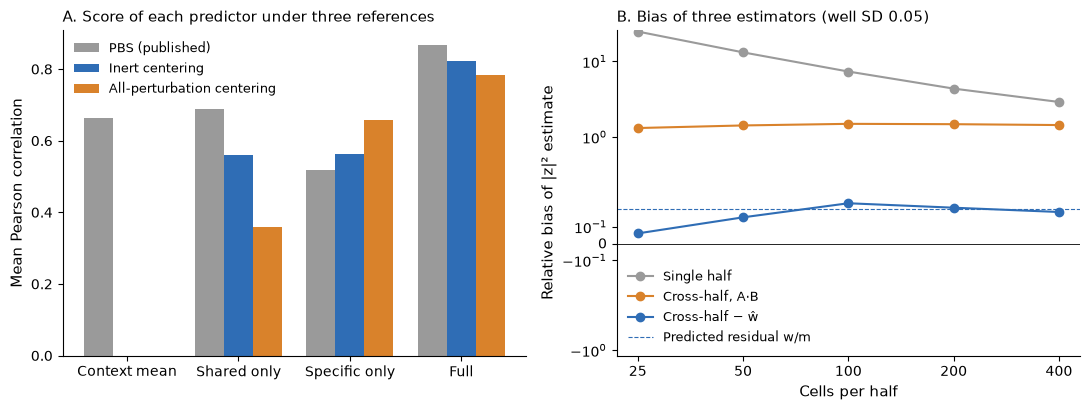

In [6]:
GREY, BLUE, ORANGE, GREEN = "#9a9a9a", "#2f6db5", "#d9822b", "#3a9a5b"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
order_p = ["Context mean", "Shared only", "Specific only", "Full"]
order_r = ["PBS (published)", "Inert centering", "All-perturbation centering"]
colors = [GREY, BLUE, ORANGE]
m = main.groupby(["predictor", "reference"])["score"].mean().unstack("reference").loc[order_p, order_r]
x = np.arange(len(order_p)); wbar = 0.26
for i, r in enumerate(order_r):
    ax.bar(x + (i - 1) * wbar, m[r].values, wbar, color=colors[i], label=r)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(order_p, fontsize=10)
ax.set_ylabel("Mean Pearson correlation", fontsize=11)
ax.set_title("A. Score of each predictor under three references", fontsize=11, loc="left")
ax.legend(fontsize=9, frameon=False)

ax = axes[1]
sub = es[es.well_sd == 0.05].groupby("n_cells")[["single_half_bias", "cross_bias", "cross_minus_w_bias"]].mean()
ax.plot(sub.index, sub["single_half_bias"], "o-", color=GREY, label="Single half")
ax.plot(sub.index, sub["cross_bias"], "o-", color=ORANGE, label="Cross-half, A·B")
ax.plot(sub.index, sub["cross_minus_w_bias"], "o-", color=BLUE, label="Cross-half − ŵ")
resid = es[es.well_sd == 0.05]["w_true"].mean() / 6 / es["true"].mean()
ax.axhline(resid, color=BLUE, ls="--", lw=0.8, label="Predicted residual w/m")
ax.axhline(0, color="black", lw=0.6)
ax.set_xscale("log"); ax.set_xticks(sub.index); ax.set_xticklabels(sub.index)
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_yscale("symlog", linthresh=0.5)
ax.set_xlabel("Cells per half", fontsize=11)
ax.set_ylabel("Relative bias of |z|² estimate", fontsize=11)
ax.set_title("B. Bias of three estimators (well SD 0.05)", fontsize=11, loc="left")
ax.legend(fontsize=9, frameon=False)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/FigS10_framework_sim.png", dpi=300)
plt.show()